In [1]:
%pip install shap lime

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


X_test: (20, 4) | y_test: (20,)
Тестовые прогнозы (первые 5): [1 0 1 1 0]
Шаги конвейера: ['preprocessor', 'model']
Очищенные признаки: ['age', 'income', 'income_per_age', 'category_A', 'category_B', 'category_C', 'category_Неизвестно']

Встроенная значимость (Feature Importance):
                Признак  Важность
0                  age  0.299565
2       income_per_age  0.297572
1               income  0.289206
3           category_A  0.034004
4           category_B  0.033856
6  category_Неизвестно  0.026587
5           category_C  0.019210


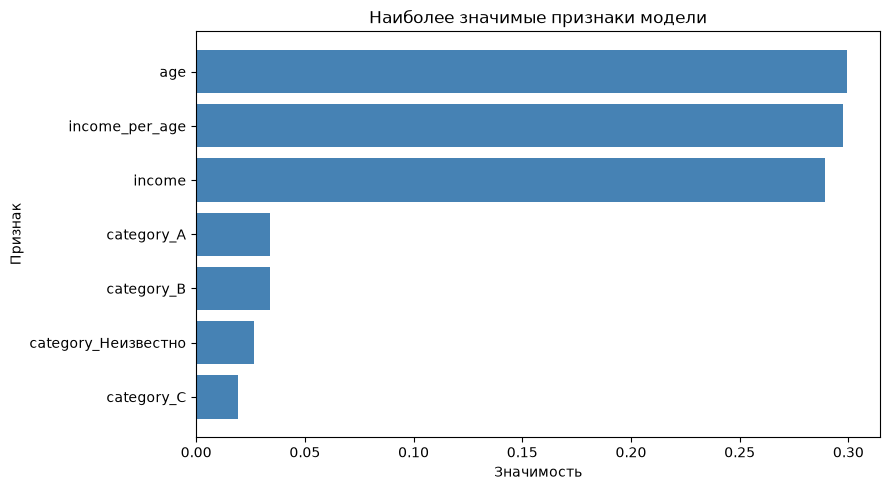


Permutation Importance:
           Признак  Средняя значимость  Стандартное отклонение
3  income_per_age            0.089411                0.073705
2        category            0.025739                0.046121
1          income            0.000599                0.069600
0             age           -0.002414                0.127057


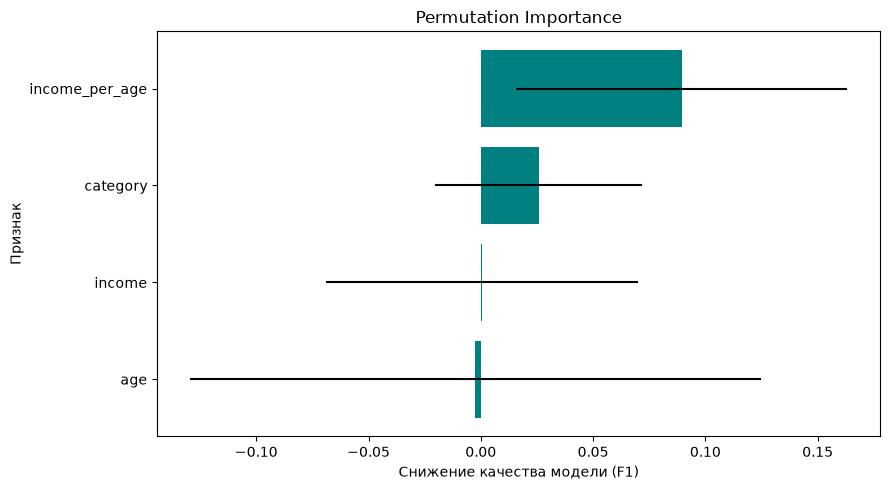

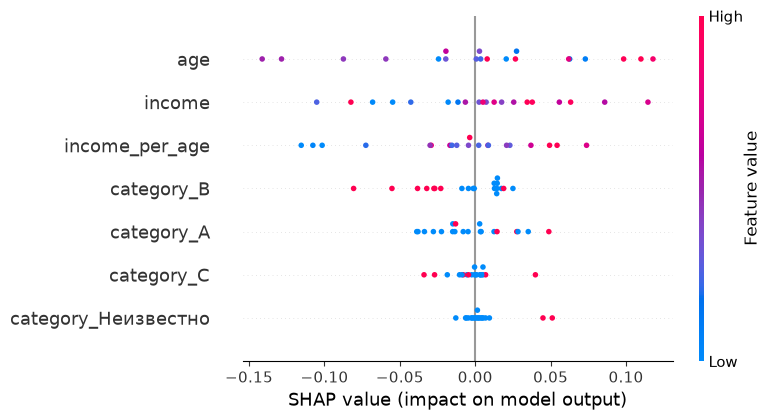

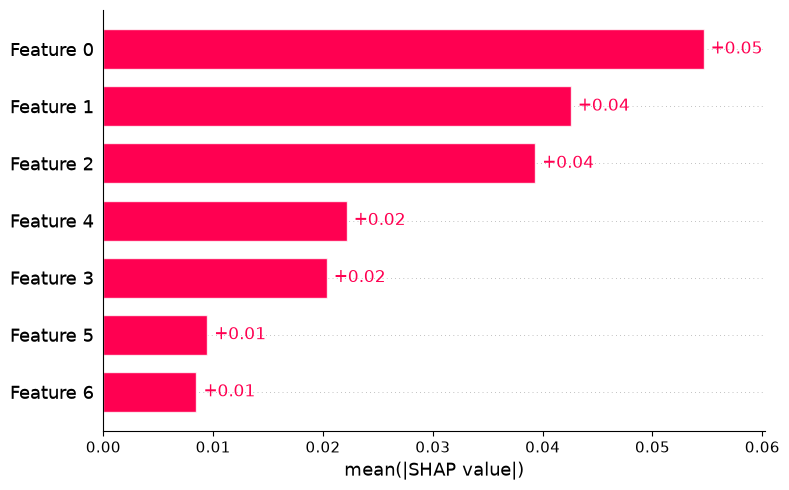


Прогноз для объекта 0: 1


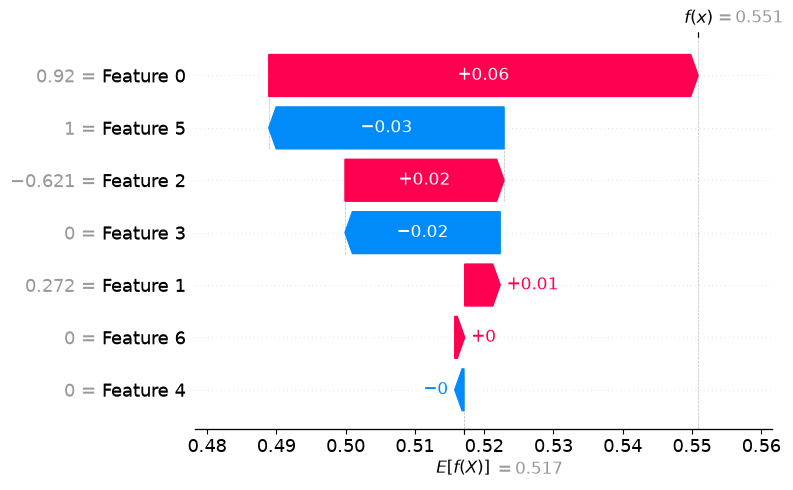

Индекс верного прогноза: 0 | Индекс ошибочного прогноза: 1


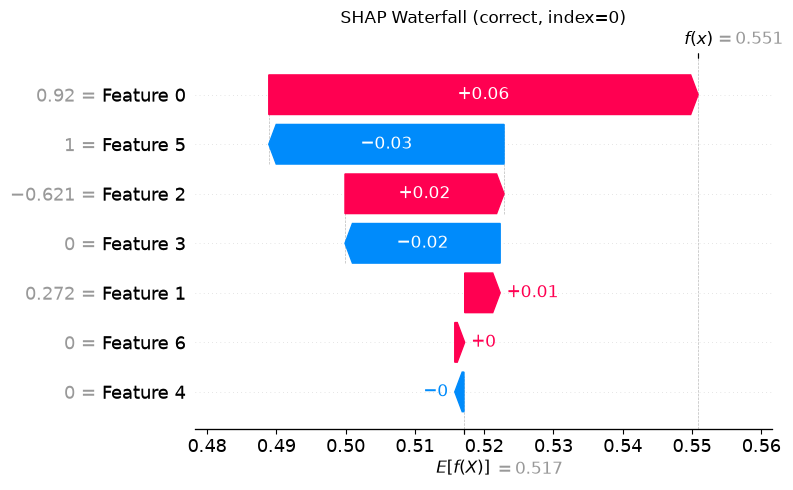

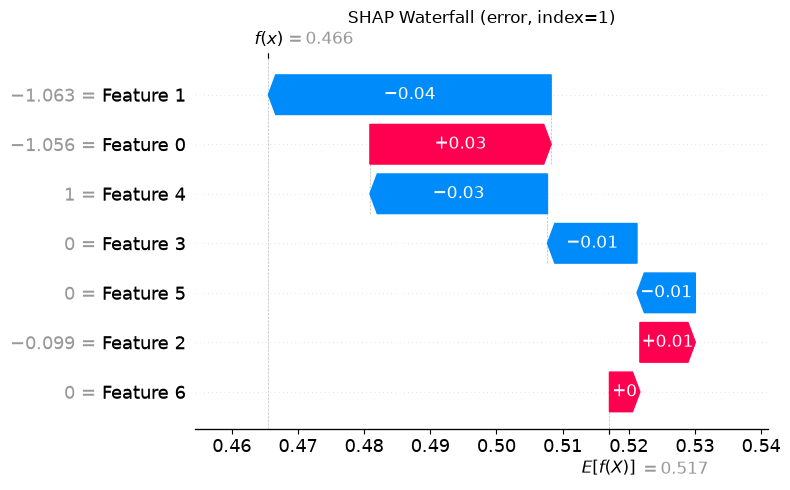

<Figure size 640x480 with 0 Axes>

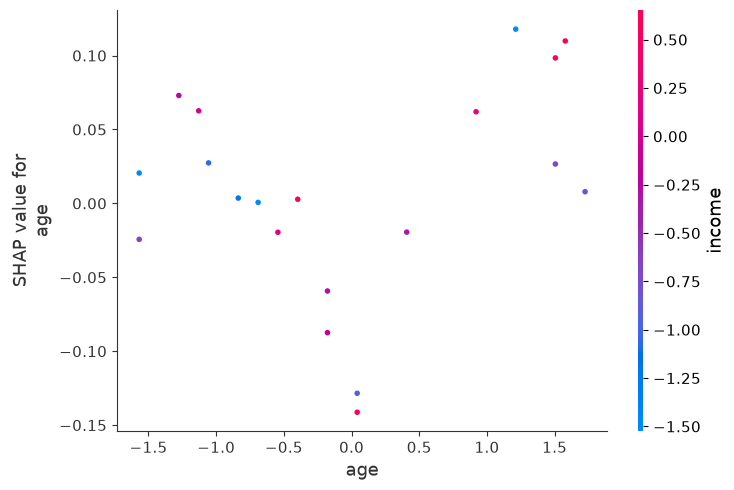

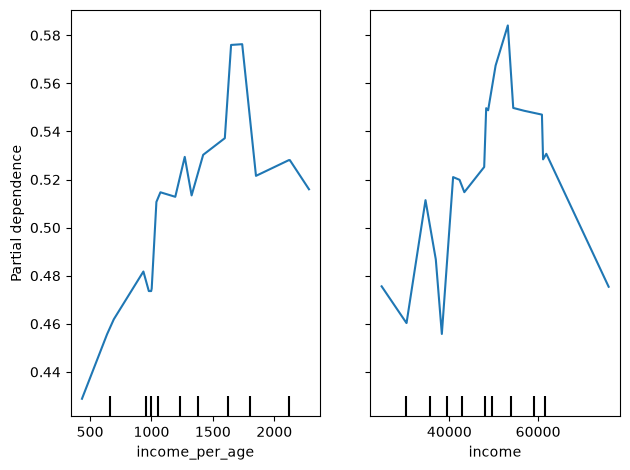


Объяснение LIME для объекта 0:
  -0.18 < age <= 0.99: -0.0601
  category_B <= 0.00: 0.0282
  category_A <= 0.00: -0.0249
  income > 0.15: -0.0225
  category_Неизвестно <= 0.00: -0.0194
  0.00 < category_C <= 1.00: -0.0120
  -0.74 < income_per_age <= -0.38: 0.0004

Проверка устойчивости прогнозов:
    Индекс  Прогноз
0       0        1
1       1        0
2       2        1
3       3        1
4       4        0

Все графики, таблицы и модуль src/interpretation/model_interpreter.py успешно сохранены!


In [3]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from pathlib import Path
from typing import Any
from lime.lime_tabular import LimeTabularExplainer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# Автоопределение корня проекта (работает и из notebooks/, и из корня ai_project/)
ROOT = Path("..") if Path("../data").exists() else Path(".")

data_dir = ROOT / "data" / "model"
model_path = ROOT / "models" / "optimized" / "optimized_model.joblib"
reports_dir = ROOT / "reports" / "model_interpretation"
src_dir = ROOT / "src" / "interpretation"

reports_dir.mkdir(parents=True, exist_ok=True)
src_dir.mkdir(parents=True, exist_ok=True)

# --- Упражнение 1. Загрузка тестовых данных и модели ---
X_test = pd.read_csv(data_dir / "X_test.csv")
y_test = pd.read_csv(data_dir / "y_test.csv").squeeze("columns")

# Если модель из 8-й лабы еще не сохранена, создаем ее на основе конвейера 5-й лабы
if not model_path.exists():
    model_path.parent.mkdir(parents=True, exist_ok=True)
    X_train = pd.read_csv(data_dir / "X_train.csv")
    y_train = pd.read_csv(data_dir / "y_train.csv").squeeze("columns")
    prep = joblib.load(ROOT / "models" / "feature_preprocessor.joblib")
    fallback_pipe = Pipeline([
        ("preprocessor", prep),
        ("model", RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42))
    ])
    fallback_pipe.fit(X_train, y_train)
    joblib.dump(fallback_pipe, model_path)

model = joblib.load(model_path)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)
print("Тестовые прогнозы (первые 5):", model.predict(X_test.head(5)))

# --- Упражнение 3. Получение названий признаков после предобработки ---
if isinstance(model, Pipeline):
    print("Шаги конвейера:", list(model.named_steps.keys()))
    preprocessor = model.named_steps.get("preprocessor")
    estimator = model.named_steps.get("model")
else:
    preprocessor = None
    estimator = model

if preprocessor is not None and hasattr(preprocessor, "get_feature_names_out"):
    feature_names = preprocessor.get_feature_names_out()
else:
    feature_names = X_test.columns.to_numpy()

clean_feature_names = [
    str(name)
    .replace("numeric__", "")
    .replace("categorical__", "")
    .replace("num__", "")
    .replace("cat__", "")
    for name in feature_names
]
print("Очищенные признаки:", clean_feature_names)

# --- Упражнения 4–5. Встроенная значимость признаков ---
feature_importance_df = None
if hasattr(estimator, "feature_importances_"):
    feature_importance_df = pd.DataFrame({
        "Признак": clean_feature_names,
        "Важность": estimator.feature_importances_
    }).sort_values("Важность", ascending=False)
    print("\nВстроенная значимость (Feature Importance):\n", feature_importance_df)

    top_features = feature_importance_df.head(15).sort_values("Важность")
    plt.figure(figsize=(9, 5))
    plt.barh(top_features["Признак"], top_features["Важность"], color="steelblue")
    plt.xlabel("Значимость")
    plt.ylabel("Признак")
    plt.title("Наиболее значимые признаки модели")
    plt.tight_layout()
    plt.savefig(reports_dir / "feature_importance.png", dpi=150)
    plt.show()
elif hasattr(estimator, "coef_"):
    coefs = np.asarray(estimator.coef_)
    coefs = np.mean(np.abs(coefs), axis=0) if coefs.ndim > 1 else np.abs(coefs)
    feature_importance_df = pd.DataFrame({
        "Признак": clean_feature_names,
        "Важность": coefs
    }).sort_values("Важность", ascending=False)
    print("\nКоэффициенты модели:\n", feature_importance_df)

# --- Упражнения 6–8. Permutation Importance и сравнение ---
scoring_metric = "f1_weighted"
perm_result = permutation_importance(
    model, X_test, y_test, scoring=scoring_metric, n_repeats=10, random_state=42, n_jobs=-1
)
permutation_df = pd.DataFrame({
    "Признак": X_test.columns,
    "Средняя значимость": perm_result.importances_mean,
    "Стандартное отклонение": perm_result.importances_std
}).sort_values("Средняя значимость", ascending=False)
print("\nPermutation Importance:\n", permutation_df)

top_perm = permutation_df.head(15).sort_values("Средняя значимость")
plt.figure(figsize=(9, 5))
plt.barh(
    top_perm["Признак"],
    top_perm["Средняя значимость"],
    xerr=top_perm["Стандартное отклонение"],
    color="teal"
)
plt.xlabel("Снижение качества модели (F1)")
plt.ylabel("Признак")
plt.title("Permutation Importance")
plt.tight_layout()
plt.savefig(reports_dir / "permutation_importance.png", dpi=150)
plt.show()

# --- Упражнения 9–15. SHAP-анализ ---
X_test_transformed = preprocessor.transform(X_test) if preprocessor is not None else X_test.to_numpy()
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

sample_size = min(500, len(X_test_transformed))
X_shap_sample = X_test_transformed[:sample_size]

if hasattr(estimator, "feature_importances_"):
    explainer = shap.TreeExplainer(estimator)
    shap_values = explainer(X_shap_sample)
else:
    predict_fn = estimator.predict_proba if hasattr(estimator, "predict_proba") else estimator.predict
    explainer = shap.Explainer(predict_fn, X_shap_sample, feature_names=clean_feature_names)
    shap_values = explainer(X_shap_sample)

# Для бинарной/многоклассовой классификации берем объяснения для целевого класса 1
shap_target = shap_values[:, :, 1] if shap_values.values.ndim == 3 else shap_values

# Упр. 11: SHAP Summary Plot
plt.figure()
shap.summary_plot(shap_target, X_shap_sample, feature_names=clean_feature_names, show=False)
plt.tight_layout()
plt.savefig(reports_dir / "shap_summary_plot.png", dpi=150, bbox_inches="tight")
plt.show()

# Упр. 12: SHAP Bar Plot
plt.figure()
shap.plots.bar(shap_target, max_display=15, show=False)
plt.tight_layout()
plt.savefig(reports_dir / "shap_bar_plot.png", dpi=150, bbox_inches="tight")
plt.show()

# Упр. 13: SHAP Waterfall Plot для объекта 0
object_index = 0
print(f"\nПрогноз для объекта {object_index}:", model.predict(X_test.iloc[[object_index]])[0])
plt.figure()
shap.plots.waterfall(shap_target[object_index], max_display=12, show=False)
plt.tight_layout()
plt.savefig(reports_dir / f"shap_waterfall_{object_index}.png", dpi=150, bbox_inches="tight")
plt.show()

# Упр. 14: Сравнение корректного и ошибочного прогнозов
preds = model.predict(X_test)
correct_idx_arr = np.where(preds == y_test.to_numpy())[0]
error_idx_arr = np.where(preds != y_test.to_numpy())[0]

correct_index = int(correct_idx_arr[0]) if len(correct_idx_arr) > 0 else 0
error_index = int(error_idx_arr[0]) if len(error_idx_arr) > 0 else 0
print(f"Индекс верного прогноза: {correct_index} | Индекс ошибочного прогноза: {error_index}")

for label, idx in [("correct", correct_index), ("error", error_index)]:
    plt.figure()
    shap.plots.waterfall(shap_target[idx], max_display=12, show=False)
    plt.title(f"SHAP Waterfall ({label}, index={idx})")
    plt.tight_layout()
    plt.savefig(reports_dir / f"shap_waterfall_{label}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Упр. 15: SHAP Dependence Plot
important_feature = feature_importance_df.iloc[0]["Признак"] if feature_importance_df is not None else clean_feature_names[0]
plt.figure()
shap.dependence_plot(
    important_feature,
    shap_target.values,
    X_shap_sample,
    feature_names=clean_feature_names,
    show=False
)
plt.tight_layout()
plt.savefig(reports_dir / "shap_dependence_plot.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Упражнение 16. Partial Dependence Plot (PDP) ---
num_cols_test = X_test.select_dtypes(include="number").columns.tolist()
important_pdp_cols = [c for c in permutation_df["Признак"] if c in num_cols_test][:2]
if important_pdp_cols:
    X_test_pdp = X_test.copy()
    X_test_pdp[num_cols_test] = X_test_pdp[num_cols_test].astype(float)
    PartialDependenceDisplay.from_estimator(model, X_test_pdp, features=important_pdp_cols)
    plt.tight_layout()
    plt.savefig(reports_dir / "partial_dependence.png", dpi=150)
    plt.show()

# --- Упражнения 17–19. LIME и проверка устойчивости ---
lime_explainer = LimeTabularExplainer(
    training_data=X_shap_sample,
    feature_names=clean_feature_names,
    class_names=[str(v) for v in sorted(y_test.unique())],
    mode="classification",
    random_state=42
)
lime_exp = lime_explainer.explain_instance(
    X_shap_sample[object_index],
    estimator.predict_proba,
    num_features=min(10, len(clean_feature_names))
)
print("\nОбъяснение LIME для объекта 0:")
for feat_rule, weight in lime_exp.as_list():
    print(f"  {feat_rule}: {weight:.4f}")

# Упр. 19: Проверка устойчивости на первых 5 объектах
stability_df = pd.DataFrame([
    {"Индекс": i, "Прогноз": model.predict(X_test.iloc[[i]])[0]}
    for i in range(min(5, len(X_test)))
])
print("\nПроверка устойчивости прогнозов:\n", stability_df)

# --- Упражнения 24–25. Функции интерпретации ---
def calculate_permutation_importance(
    trained_model: Any,
    features: pd.DataFrame,
    target: pd.Series,
    scoring: str,
    repeats: int = 10
) -> pd.DataFrame:
    if len(features) != len(target):
        raise ValueError("Размеры признаков и целевой переменной не совпадают")
    res = permutation_importance(
        trained_model, features, target, scoring=scoring, n_repeats=repeats, random_state=42, n_jobs=-1
    )
    return pd.DataFrame({
        "feature": features.columns,
        "importance_mean": res.importances_mean,
        "importance_std": res.importances_std
    }).sort_values("importance_mean", ascending=False)

def explain_prediction(trained_model: Any, data: pd.DataFrame, row_index: int) -> dict:
    if row_index < 0 or row_index >= len(data):
        raise IndexError("Индекс объекта находится за пределами данных")
    selected_row = data.iloc[[row_index]]
    pred = trained_model.predict(selected_row)[0]
    res = {
        "row_index": int(row_index),
        "prediction": int(pred) if isinstance(pred, (np.integer, int)) else float(pred)
    }
    if hasattr(trained_model, "predict_proba"):
        probs = trained_model.predict_proba(selected_row)[0]
        res["probabilities"] = [round(float(p), 4) for p in probs]
    return res

# --- Упражнение 26. Создание модуля src/interpretation/model_interpreter.py ---
module_code = '''from pathlib import Path
from typing import Any
import joblib
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance


def calculate_permutation_importance(
    trained_model: Any,
    features: pd.DataFrame,
    target: pd.Series,
    scoring: str = "f1_weighted",
    repeats: int = 10
) -> pd.DataFrame:
    if len(features) != len(target):
        raise ValueError("Размеры признаков и целевой переменной не совпадают")
    result = permutation_importance(
        trained_model,
        features,
        target,
        scoring=scoring,
        n_repeats=repeats,
        random_state=42,
        n_jobs=-1
    )
    return pd.DataFrame({
        "feature": features.columns,
        "importance_mean": result.importances_mean,
        "importance_std": result.importances_std
    }).sort_values("importance_mean", ascending=False)


def explain_prediction(
    trained_model: Any,
    data: pd.DataFrame,
    row_index: int
) -> dict:
    if row_index < 0 or row_index >= len(data):
        raise IndexError("Индекс объекта находится за пределами данных")
    selected_row = data.iloc[[row_index]]
    prediction = trained_model.predict(selected_row)[0]
    result: dict[str, Any] = {
        "row_index": int(row_index),
        "prediction": int(prediction) if isinstance(prediction, (np.integer, int)) else float(prediction)
    }
    if hasattr(trained_model, "predict_proba"):
        probabilities = trained_model.predict_proba(selected_row)[0]
        result["probabilities"] = [round(float(v), 4) for v in probabilities]
    return result


class ModelInterpreter:
    def __init__(self, model_path: str) -> None:
        path = Path(model_path)
        if not path.exists():
            raise FileNotFoundError(f"Модель не найдена: {path}")
        self.model = joblib.load(path)

    def predict(self, data: pd.DataFrame):
        return self.model.predict(data)

    def global_importance(
        self,
        data: pd.DataFrame,
        target: pd.Series,
        scoring: str = "f1_weighted"
    ) -> pd.DataFrame:
        return calculate_permutation_importance(self.model, data, target, scoring)

    def explain_row(self, data: pd.DataFrame, row_index: int) -> dict:
        return explain_prediction(self.model, data, row_index)
'''

(src_dir / "__init__.py").write_text("", encoding="utf-8")
(src_dir / "model_interpreter.py").write_text(module_code, encoding="utf-8")

# --- Упражнение 27. Сохранение таблиц и локального объяснения ---
permutation_df.to_csv(reports_dir / "permutation_importance.csv", index=False, encoding="utf-8-sig")
if feature_importance_df is not None:
    feature_importance_df.to_csv(reports_dir / "built_in_feature_importance.csv", index=False, encoding="utf-8-sig")

local_exp = explain_prediction(model, X_test, object_index)
with open(reports_dir / "local_explanation.json", "w", encoding="utf-8") as f:
    json.dump([local_exp], f, ensure_ascii=False, indent=2)

print("\nВсе графики, таблицы и модуль src/interpretation/model_interpreter.py успешно сохранены!")